In [1]:
# Required Python packages
from datetime import date, datetime, timedelta
import calendar
import pandas as pd
import numpy as np
import itertools
import copy
from numpy.linalg import multi_dot
from scipy.stats import norm
from scipy.stats import bernoulli
from scipy.optimize import fmin_slsqp as min

import tensorflow
import tensorflow.keras as keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow.keras.optimizers as opt
from tensorflow.keras import backend as keras_backend

# import keras
# from keras.models import Sequential
# from keras.layers import Dense
# from keras import layers
# from keras.callbacks import EarlyStopping
# import keras.optimizers as opt
# from keras import backend as keras_backend

import matplotlib.pyplot as plt
import math


#Import Date opertative user defined functions
from ipynb.fs.full.user_defined_vik_functions import get_all_monthly_option_expiries, \
                                                     find_last_thurs_date_of_month, \
                                                     prev_workday_if_holiday, find_wkly_expries,\
                                                     date_of_prev_thurs

# Import dataframe naming functions 
from ipynb.fs.full.user_defined_vik_functions import get_mthly_df_name_from_expiry

#Import data loading functions
from ipynb.fs.full.user_defined_vik_functions import load_all_mthly_data

#import traded options parameters and info
from ipynb.fs.full.user_defined_vik_functions import generate_weekly_strikes, generate_mthly_strikes

#Import pricing functions
from ipynb.fs.full.user_defined_vik_functions import BSM_call_vec, BSM_put_vec

#Import implied volatility processing functions
from ipynb.fs.full.user_defined_vik_functions import generate_weekly_iv, gen_interpolated_iv

#Import Risk-free interest rate generation functions
from ipynb.fs.full.user_defined_vik_functions import generate_weekly_ir

#Import Stochatic process simulation functions
from ipynb.fs.full.user_defined_vik_functions import gbm1W_simulation, generate_covariance_from_correlation


NotFoundError: /opt/tljh/user/lib/python3.7/site-packages/tensorflow/core/kernels/libtfkernel_sobol_op.so: undefined symbol: _ZN10tensorflow14kernel_factory17OpKernelRegistrar12InitInternalEPKNS_9KernelDefEN4absl12lts_2021032411string_viewESt10unique_ptrINS0_15OpKernelFactoryESt14default_deleteIS9_EE

In [8]:
# Stock Index of Interest
stock_ident = "BANKNIFTY"

# The scope of this code is to hedge one option 
# and scope will be extended to a portfolio
no_of_assets = 1
cor_mat = [[1]]

#Path to refer data
source_path = "/home/jupyter-partha/Vikranth - Chapter 2/"
input_sub_path = "Input Data/mkt_data_covid_region/"
output_sub_path = "Output Data/"
input_data_path = source_path + input_sub_path
output_data_path = source_path + output_sub_path

#Static hedging performed at different moneyness regions 
#i.e. moneyness is used to select the option with nearest moneyness match
# ATM - At the Money, ITM - In the money, OTM - Out of the Money
prod_moneyness = "ATM"

#Product type to hedge: either "CE" or "PE"
prod_type = "CE"

# Periods of interest will be a dictionary
#Key is the year, value is a list of months 1-12, 1- Jan, 2 - Feb,...12 - Dec
# For E.g., periods_of_interest = {2020: [3], 2019: [11, 12]}
periods_of_interest = {2020: [3]}

#List of holidays
holidays_list = [date(2020, 3, 10)]

#Simulation Parameters
no_of_paths = 5000
#Initialisation of Neural Network hyperparameters for pre-training network
batch_size_divisor = 10
no_of_epochs = 1000 # keep 10 for debugging coding errors
no_of_output_nodes = no_of_assets
batch_size = int(no_of_paths/batch_size_divisor)

#No_of_options to hedge
no_opt = 1


In [9]:
#Function to price European call options
def pricer_vanilla_by_nn(sim_stock_mat, option_type, opt_strike, dt, \
                         r, vol, nnet_model, batch_size, no_of_epochs, week, no_of_wks,spot):

    # Current stock price is at index 0. This extracts stock price at the next time step
    stock_vec = sim_stock_mat[:, 1]
        
    # The following steps extract option value/pay-off at the next week
    if (option_type == "CE" and week != no_of_wks-1):
        option_value = BSM_call_vec(stock_vec, opt_strike, r, vol, dt) * no_opt
    elif (option_type == "PE" and week != no_of_wks-1):
        option_value = BSM_put_vec(stock_vec, opt_strike, r, vol, dt) * no_opt

    elif (option_type == "CE" and week == no_of_wks-1):
        option_value = np.maximum(stock_vec - opt_strike, 0) * no_opt
    else:
        option_value = np.maximum(opt_strike - stock_vec, 0) * no_opt
    
    option_value = np.asarray(option_value)
    option_value = option_value.reshape(-1, 1)
        
        
    #Creating the training data for the neural network model
    # Neural Network Function using RELU activaion function
    # Build Neural Network model(using Stock prices at next exercise time step and their option value)   
    X_train = stock_vec
    X_train = X_train.reshape(-1, 1)

    Y_train = option_value
    Y_train = np.asarray(Y_train)
    Y_train.reshape(-1, 1)
    
 
    nnet_output = nnet_model.fit(X_train, Y_train, epochs=no_of_epochs, batch_size=batch_size, 
                                 verbose=0, validation_split=0.3)
    
    XX = X_train * spot
    YY = Y_train * spot
    YY_pred = nnet_model.predict(X_train) * spot
    plt.plot(XX, YY, 'r.')
    plt.plot(XX, YY_pred, 'b.')
    plt.show()

    pfl_weights = np.array(nnet_model.layers[1].get_weights())
            
    return pfl_weights


def pre_train_nn(sim_stock_mat, option_type, \
                 opt_strike, dt, \
                 nnet_model, batch_size, no_of_epochs):

    stock_vec = sim_stock_mat[:, 1]
        
    # The following steps extract option value/pay-off at the next time step
    if (option_type == "CE"):
        option_value = np.maximum(stock_vec - opt_strike, 0) * no_opt
    else:
        option_value = np.maximum(opt_strike - stock_vec, 0) * no_opt
        
    option_value = np.asarray(option_value)
    option_value = option_value.reshape(-1, 1)
        
    #Creating the training data for the neural network model
    # Neural Network Function using RELU activaion function
    # Build Neural Network model(using Stock prices at next exercise time step and their option value)
    X_train = stock_vec
    X_train = X_train.reshape(-1, 1)

    Y_train = option_value
    Y_train = np.asarray(Y_train)
    Y_train.reshape(-1, 1, 1)

    nnet_output = nnet_model.fit(X_train, Y_train, epochs=no_of_epochs, batch_size=batch_size, verbose=0, validation_split=0.3)

    return nnet_model


In [13]:
#########################
#User-defined functions #
#########################

def generate_weekly_static_pfl_weights(no_of_paths, mthly_expiries_list, \
                                       dict_wkly_expiries_each_month, \
                                       dict_ce_wkly_strikes, dict_pe_wkly_strikes, \
                                       dict_wkly_spots, dict_wkly_iv, \
                                       prod_type, prod_moneyness, output_path, \
                                       option_type = "CE", no_of_assets=1, cor_mat=[[1]],\
                                       batch_size_divisor=10, no_of_epochs = 1000):
    ce_pfl_weights = []
    pe_pfl_weights = [] 
    cash_weights = []
    iv_mny_list = []
    for each_month in mthly_expiries_list:
        strike = dict_mthly_strikes[each_month.strftime("%d-%b-%Y")] 
        
        weekly_pfl_weights = []
        ce_dict = {}
        pe_dict = {}
        cash_dict = {}
        pred_list = []
        week_list = dict_wkly_expiries_each_month[each_month.strftime("%d-%b-%Y")]
        no_of_weeks = len(week_list)
        
        for week in range(0, no_of_weeks):
#         for week in range(0, 1):
            spot = dict_wkly_spots[each_month.strftime("%d-%b-%Y")][week]
            s_t = 1
            K = strike / spot
            if (week == 3):
                sim_start_date = dict_wkly_expiries_each_month[each_month.strftime("%d-%b-%Y")][week]
                sim_end_date = each_month
                #This doesn't matter - as in the last week, BS formula equals to pay-off. Vol and r are just inputs
                vol_list = np.array([dict_wkly_iv[each_month.strftime("%d-%b-%Y")][week]])
                r = np.array([dict_wkly_ir[each_month.strftime("%d-%b-%Y")][week]])
            else:
                sim_start_date = dict_wkly_expiries_each_month[each_month.strftime("%d-%b-%Y")][week]
                sim_end_date = dict_wkly_expiries_each_month[each_month.strftime("%d-%b-%Y")][week + 1]
                vol_list = np.array([dict_wkly_iv[each_month.strftime("%d-%b-%Y")][week+1]]) 
                r = np.array([dict_wkly_ir[each_month.strftime("%d-%b-%Y")][week+1]])
                
#                 if (week==0):
#                     print("Vol:", np.array([dict_wkly_iv[each_month.strftime("%d-%b-%Y")][week+1]]))
         
            sim_stock_mat = gbm1W_simulation(no_of_paths, sim_start_date, sim_end_date, \
                                             no_of_assets, s_t, r, vol_list, cor_mat)
            
            
            call_strikes_hdge_list_pos = (np.sort(np.array(dict_ce_wkly_strikes[each_month.strftime("%d-%b-%Y")][week])) / spot) * (-1)
            call_strikes_hdge_list = call_strikes_hdge_list_pos.tolist()
            put_strikes_hdge_list_pos = (np.sort(np.array(dict_pe_wkly_strikes[each_month.strftime("%d-%b-%Y")][week])) / spot)
            put_strikes_hdge_list = put_strikes_hdge_list_pos.tolist()
            no_of_hidden_nodes = len(call_strikes_hdge_list) + len(put_strikes_hdge_list)
            
            call_weights = list(np.ones(len(call_strikes_hdge_list)))
            put_weights = list(-1 * np.ones(len(put_strikes_hdge_list)))
            static_layer_weights = call_weights + put_weights
            static_node_weights = call_strikes_hdge_list + put_strikes_hdge_list
            static_weights = [np.array([static_layer_weights]), np.array(static_node_weights)]
            
#             if (week==0):
#                 df_out = pd.DataFrame({"Strikes":static_node_weights, "Weights":static_layer_weights})
#                 df_out.to_csv(output_data_path + "B3_" + "intermediate_nn_params.csv", index = False)
            
            nnet_model = Sequential()
            hidden_layer = Dense(no_of_hidden_nodes, activation='relu', input_dim=no_of_assets)
            hidden_layer.trainable = False
            nnet_model.add(hidden_layer)
            nnet_model.layers[0].set_weights(static_weights) 
#             output_layer = Dense(no_of_output_nodes, activation='linear', kernel_initializer='normal', use_bias=True, kernel_constraint=keras.constraints.NonNeg())
            
            outer_initializer = tensorflow.keras.initializers.Constant(value=(1/no_of_hidden_nodes))
            output_layer = Dense(no_of_output_nodes, activation='linear', kernel_initializer=outer_initializer, use_bias=True)
            
            output_layer.trainable = True
            nnet_model.add(output_layer)
            nnet_model.compile(optimizer=opt.Adam(lr=0.001), loss='mean_squared_error')
            
            dt = float((each_month - sim_end_date).days) / 365
#             dt = float((sim_end_date - sim_start_date).days) / 365
            batch_size = int(no_of_paths/batch_size_divisor)
            
            
            df_daily_iv_data = pd.read_csv(output_path + "A1_Daily_vol_smile_" + option_type + "_" + each_month.strftime("%d-%b-%Y") + ".csv")
            spot_list = sim_stock_mat[:,1]
            mny_list = spot_list / K

            if (week != no_of_weeks-1):
                date_str = sim_end_date.strftime("%d-%b-%Y")
                gen_iv = lambda x: gen_interpolated_iv(df_daily_iv_data, date_str, x)
                gen_iv = np.vectorize(gen_iv)
                vol_arr = gen_iv(mny_list)
#                 date_list = [date_str for i in range(0, len(spot_list))]
#                 df_out = pd.DataFrame({"Date":date_list, "Mny_list": mny_list, "Impl Vol": vol_arr})
#                 iv_mny_list.append(df_out)
            else:
                vol_arr = np.array([0]) 

            nnet_model = pre_train_nn(sim_stock_mat, option_type, \
                                      K, dt, nnet_model, batch_size, no_of_epochs=100)
        
            #Fina Params adjustment for the final neural networks
            keras_backend.set_value(nnet_model.optimizer.lr, 5e-4)

            ######################################################################################
            ### Portfolio weights of shorter term options from neural network of European options ###
            ######################################################################################

            pfl_weights  = pricer_vanilla_by_nn(sim_stock_mat, option_type, K, dt, \
                          r, vol_arr, nnet_model, batch_size, no_of_epochs, week, no_of_weeks, spot)
            
            ce_dates_list = [sim_start_date.strftime("%d-%b-%Y") for i in range(0, len(call_strikes_hdge_list))]
            ce_wt_list = np.array(pfl_weights[0]).reshape(-1)[0:len(call_strikes_hdge_list)]
            ce_wkly_strikes = (np.sort(np.array(dict_ce_wkly_strikes[each_month.strftime("%d-%b-%Y")][week]))) 
            ce_wkly_strikes = list(ce_wkly_strikes)
            ce_dict = {"Date": ce_dates_list, "Strike": ce_wkly_strikes, "Pfl_weights": ce_wt_list}
            df_ce = pd.DataFrame(ce_dict)
            ce_pfl_weights.append(df_ce)
            
            pe_wt_list = np.array(pfl_weights[0]).reshape(-1)[len(call_strikes_hdge_list):]
            pe_dates_list = [sim_start_date.strftime("%d-%b-%Y") for i in range(0, len(put_strikes_hdge_list))]
            pe_wkly_strikes = (np.sort(np.array(dict_pe_wkly_strikes[each_month.strftime("%d-%b-%Y")][week])))
            pe_wkly_strikes = list(pe_wkly_strikes)
            pe_dict = {"Date": pe_dates_list, "Strike":pe_wkly_strikes, "Pfl_weights": pe_wt_list}
            df_pe = pd.DataFrame(pe_dict)
            pe_pfl_weights.append(df_pe)
            
            cash_date = [sim_start_date.strftime("%d-%b-%Y")]
            cash_weight = np.array(pfl_weights[1][0]) * spot
            cash_dict = {"Date":cash_date, "Pfl_weights":cash_weight} 
            df_cash = pd.DataFrame(cash_dict)
            cash_weights.append(df_cash)
            
            if (week == 0):
                model_week = nnet_model
            
        df_ce_pfl_weights = pd.concat(ce_pfl_weights, axis=0)
        df_pe_pfl_weights = pd.concat(pe_pfl_weights, axis=0)
        df_cash_pfl_weights = pd.concat(cash_weights, axis=0)
#         df_iv_used = pd.concat(iv_mny_list, axis=0)
#         df_pred_val = pd.concat(pred_list, axis=0)
        
        df_ce_pfl_weights.to_csv(output_path  + "B3_" + prod_moneyness + "_" + "CE_Pfl_weights" + ".csv", index = False)
        df_pe_pfl_weights.to_csv(output_path + "B3_" + prod_moneyness + "_" + "PE_Pfl_weights" + ".csv", index = False)
        df_cash_pfl_weights.to_csv(output_path  + "B3_" +  prod_moneyness + "_" + "Cash_Pfl_weights" + ".csv", index = False)
#         df_iv_used.to_csv(output_path  + "B3_" +  prod_moneyness + "_" + "iv_used_acr_mnys" + ".csv", index = False)
#         df_pred_val.to_csv(output_path  + "B3_" +  prod_moneyness + "_" + "df_pred" + ".csv", index = False)

    return df_ce_pfl_weights, df_pe_pfl_weights, df_cash_pfl_weights, model_week

def output_strikes_hedged(prod_type, dict_mthly_strikes, output_path):
    list_of_dates = []
    list_of_prod_type = []
    list_of_strikes = []
    for each_month in dict_mthly_strikes.keys():
        list_of_dates.append(each_month)
        list_of_strikes.append(dict_mthly_strikes[each_month])
        list_of_prod_type.append(prod_type)
    dict_hedged_prod = {"Date":list_of_dates, "prod_type":list_of_prod_type, "Strike":list_of_strikes}
    df_hedged_prod = pd.DataFrame(dict_hedged_prod) 
    df_hedged_prod.to_csv(output_path + "B3_" + prod_type + "_" + "strikes_hedged.csv", index = False)
    return(df_hedged_prod)


ipynb.fs.full.user_defined_vik_functions:396: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


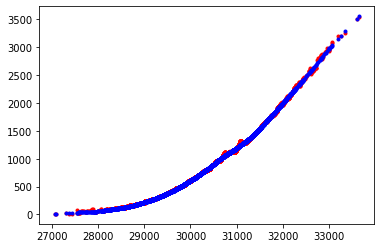

/opt/tljh/user/lib/python3.7/site-packages/ipykernel_launcher.py:44: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray


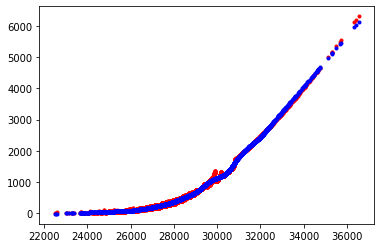

/opt/tljh/user/lib/python3.7/site-packages/ipykernel_launcher.py:44: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray


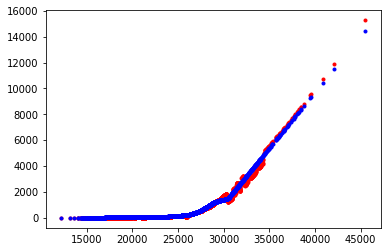

/opt/tljh/user/lib/python3.7/site-packages/ipykernel_launcher.py:44: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray


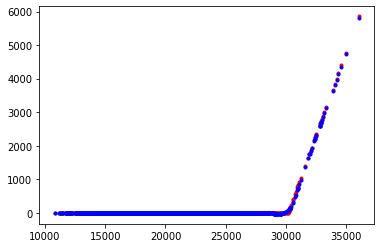

/opt/tljh/user/lib/python3.7/site-packages/ipykernel_launcher.py:44: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray


In [14]:

#Find the monthly strikes of option from mkt data to find the option to be hedged
#Every month, an option is hedged
mthly_expiries_list = get_all_monthly_option_expiries(periods_of_interest, holidays_list)
dict_wkly_expiries_each_month = find_wkly_expries(mthly_expiries_list, holidays_list)

#Load all monthly mkt data
mthly_mkt_data = load_all_mthly_data(mthly_expiries_list, input_data_path, prod_type_lists=["FUT", "CE", "PE"], stock_ident=stock_ident)

#Load weekly strikes of short term options used for hedging monthly options 
dict_ce_wkly_strikes, dict_pe_wkly_strikes, dict_wkly_spots = generate_weekly_strikes(dict_wkly_expiries_each_month, input_data_path, stock_ident = "BANKNIFTY")     

#Load monthly strikes of interest as of required moneyness on the begining of month
dict_mthly_strikes = generate_mthly_strikes(mthly_mkt_data, prod_moneyness, prod_type, holidays_list, stock_ident=stock_ident)

#Load weekly IV for Black-Scholes model input and monte-carlo simulation of stock paths
dict_wkly_iv = generate_weekly_iv(dict_wkly_expiries_each_month, dict_wkly_spots, dict_mthly_strikes, prod_type, output_path=output_data_path, atm_ind=0)
# print(dict_wkly_iv)

#Load weekly risk free interest rates from futures
#This function to be changed based on updates on risk-free-interest - now kept it as cosntant
dict_wkly_ir = generate_weekly_ir(dict_wkly_expiries_each_month, mthly_mkt_data, stock_ident)

# #Load Static portfolio weights built by neural network
ce_pfl_wts, pe_pfl_wts, cash_pfl_wts, nnet_model = generate_weekly_static_pfl_weights(no_of_paths, mthly_expiries_list, dict_wkly_expiries_each_month, \
                                                        dict_ce_wkly_strikes, dict_pe_wkly_strikes, dict_wkly_spots, \
                                                        dict_wkly_iv, prod_type, prod_moneyness, output_data_path, \
                                                        option_type = prod_type, no_of_assets=no_of_assets, cor_mat=cor_mat,\
                                                        batch_size_divisor=batch_size_divisor, no_of_epochs = no_of_epochs) 


# # The strike correspnding to the option that is hedged
df_hedged_prod = output_strikes_hedged(prod_type, dict_mthly_strikes, output_data_path)


In [16]:
##############
# Rough Work #
##############

# 30187
# 29147.15
# 28868.4
# 29177.05
# 28653.7
# 28815.35

print(nnet_model.predict(np.array(30187/30187).reshape(-1)) * 30187) 
print(nnet_model.predict(np.array(29147.15/30187).reshape(-1)) * 30187) 
print(nnet_model.predict(np.array(28868.4/30187).reshape(-1)) * 30187) 
print(nnet_model.predict(np.array(29177.05/30187).reshape(-1)) * 30187) 
print(nnet_model.predict(np.array(28653.7/30187).reshape(-1)) * 30187) 
print(nnet_model.predict(np.array(28815.35/30187).reshape(-1)) * 30187) 



[[706.03845]]
[[256.61813]]
[[183.08365]]
[[264.7229]]
[[137.17578]]
[[169.88892]]


In [ ]:
167